<a href="https://colab.research.google.com/github/erguenasli/eniac_discount_strategy/blob/main/eniac_discount_strategy_googlecolab_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ENIAC Discount Strategy & Revenue Optimization: Mitigating Capital Leakage in E-Commerce**

## 1. Executive Summary & Problem Framing

### 1.1 Executive Summary

This analysis evaluates ENIAC's discounting practices to establish an evidence-based promotional strategy. It resolves a core internal debate regarding commercial policy: whether aggressive discounting should be capped universally (or restricted strictly to clearance/used stock), or whether deep discounts serve as vital volume drivers when applied selectively.

The transactional evidence reveals that evaluating discounts purely by percentage markdowns creates a dangerous distortion. While clearance and opened-box items naturally command the highest percentage cuts (20%–33%) to facilitate asset recovery, universally capping discounts across new inventory overlooks underlying unit economics. Deep discounts on new, low-ticket accessories (25%–28%) account for high transaction volumes while generating negligible cash leakage (<€126k total per category). In contrast, seemingly conservative discounts (9.7%) on Mac Computers surrendered €682,024 in raw cash margin. A sound discount framework must not simply ban deep markdowns; it must enforce a strict 5%–7% ceiling on flagship hardware, reserve liquidation-level cuts for secondary stock and deploy high-percentage discounts on high-margin accessories to protect conversion.

### 1.2 Problem Framing: The Strategic Dilemma: Two Competing Views

Within the commercial team, two contrasting viewpoints emerged regarding future pricing policy:

1. The Margin Protection Hypothesis: Aggressive percentage discounts (e.g., >20%) dilute brand value and erode retail margins. Proponents argue for a blanket cap on deep markdowns across the catalog, restricting 20%+ price reductions exclusively to "Secondhand" and "Opened" inventory to clear unsellable assets without tarnishing brand new product lines.

2. The Portfolio & Unit Economics Hypothesis: Discounts must be evaluated by absolute cash loss and product margin structure, not flat percentage rates. Proponents argue that eliminating steep accessory discounts hurts basket conversion and customer acquisition to save trivial sums of money, while failing to address where true margin leakage occurs: low-percentage discounts on high-ticket hardware.


### 1.3 Core Analytical Questions

* Do aggressive discounts actually harm
margin where they occur? Is cash leakage driven by steep percentage markdowns on everyday products, or by low-percentage trims on big-ticket devices?
* Is deep discounting truly confined to used goods today? To what extent are heavy discounts already an operational necessity for clearance versus a tool for new product sales?
* What are the downstream risks of a blanket discount cap? If double-digit discounts are eliminated outside of used inventory, does the business risk inventory stagnation and lower order volume in exchange for negligible margin recovery?

### 1.4 Analytical Objective

To assess transactional sales, catalog pricing and realized margins across all categories, determining whether discounting policy should be governed by a universal percentage cap or a category-specific, ticket-size framework.

## 2. Robust Data Pipeline & Quality Control

### 2.1 Environment Setup & Configuration

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Optional:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_rows', 1000)

### 2.2 Raw Data Ingestion

In [ ]:
file_ids = {
    'brands': '1WOT0Z2M7-6yjHYirDPyo0LzsVVA641u_',
    'orderlines': '15LSEuE7QiwIR_Sq9lqiM77jxBPDB6HoA',
    'orders': '16946YPUGreB_TnFYLwjc6UvLrJMbQJgd',
    'products': '1D5COJ5MHQIUt_Y-F9s3mj9q2lf5CBj8V'
}

base_url = 'https://drive.google.com/uc?export=download&id='

brands = pd.read_csv(base_url + file_ids['brands'])
orderlines = pd.read_csv(base_url + file_ids['orderlines'])
orders = pd.read_csv(base_url + file_ids['orders'])
products = pd.read_csv(base_url + file_ids['products'])

### 2.3 Data Cleaning Functions

In [ ]:
# ===========================================================================
# 2.3.1 Independent Cleaning: Orderlines & Orders
# ===========================================================================

# Clean orderlines
orderlines_clean = (
    orderlines.drop(columns=['id', 'product_id'], errors='ignore')
    .assign(
        date=lambda x: pd.to_datetime(x['date']),
        month=lambda x: x['date'].dt.month,
        month_abbr=lambda x: x['date'].dt.strftime('%b'),
        day=lambda x: x['date'].dt.day,
        day_abbr=lambda x: x['date'].dt.strftime('%a'),
        # Fix corrupted dot-separated prices (e.g., '1.137.99' -> '1137.99')
        unit_price=lambda x: pd.to_numeric(
            x['unit_price'].astype(str).str.replace(r'^(\d+)\.(\d{3}\.\d{2})$', r'\1\2', regex=True),
            errors='coerce'
        )
    )
)

# Correct 1000x decimal scale shifts and drop invalid/negative amounts
orderlines_clean.loc[orderlines_clean['unit_price'] > 20_000, 'unit_price'] = (
    orderlines_clean.loc[orderlines_clean['unit_price'] > 20_000, 'unit_price'] / 1_000
).round(2)
orderlines_clean = orderlines_clean[orderlines_clean['unit_price'] > 0].copy()

# Clean orders
orders_clean = (
    orders.dropna()
    .loc[lambda x: (x['state'] == 'Completed') & (x['total_paid'] != 0)]
    .assign(
        created_date=lambda x: pd.to_datetime(x['created_date']),
        month=lambda x: x['created_date'].dt.month,
        month_abbr=lambda x: x['created_date'].dt.strftime('%b'),
        day=lambda x: x['created_date'].dt.day,
        day_of_week=lambda x: x['created_date'].dt.strftime('%a')
    )
    .copy()
)

In [ ]:
# ===========================================================================
# 2.3.2 Data Cleaning Functions: Products
# ===========================================================================

def clean_price_string(val):
    """
    Parses corrupted numeric strings from raw catalog prices:
    - Multiple periods (thousands separators + decimals)
    - 3+ decimal place errors (shifted decimal point)
    """
    if pd.isna(val) or val is None:
        return np.nan

    s = str(val).strip()
    if s == '' or s.lower() == 'nan':
        return np.nan

    dot_count = s.count('.')

    # Multi-dot formatting (e.g., '2.289.998' -> 228.99)
    if dot_count >= 2:
        digits_only = s.replace('.', '')
        return round(float(digits_only) / 10_000, 2)

    # Single-dot with shifted decimals (e.g., '129.906' -> 12.99)
    if dot_count == 1:
        integer_part, decimal_part = s.split('.')
        if len(decimal_part) >= 3:
            digits_only = integer_part + decimal_part
            return round(float(digits_only) / 10_000, 2)
        return round(float(s), 2)

    return float(s)


def clean_products(products, orderlines):
    """
    Cleans raw catalog products:
    1. Removes duplicate rows and deduplicates SKUs programmatically.
    2. Imputes missing text metadata.
    3. Normalizes decimal point corruptions in price fields.
    4. Anchors catalog prices against realized transaction unit prices.
    5. Corrects order-of-magnitude scaling anomalies in promo and list prices.
    6. Filters for valid sold products within standard promo bounds (0.20 - 1.00).
    """
    # Deduplication & missing value imputation
    products_clean = (
        products.drop_duplicates()
        .drop_duplicates(subset=['sku'], keep='first')
        .assign(
            type=lambda x: x['type'].fillna('Unknown'),
            desc=lambda x: x['desc'].fillna('Unknown')
        )
    )

    # Parse price fields
    products_clean['price'] = products_clean['price'].apply(clean_price_string)
    products_clean['promo_price'] = products_clean['promo_price'].apply(clean_price_string)

    # Anchor against realized orderlines to detect magnitude errors
    unit_price_anchor = (
        orderlines.groupby('sku', as_index=False)['unit_price']
        .mean()
        .rename(columns={'unit_price': 'unit_price_mean'})
    )
    products_clean = products_clean.merge(unit_price_anchor, on='sku', how='inner')

    # Calculate initial catalog price ratio
    products_clean['price_ratio'] = products_clean['promo_price'] / products_clean['price'].replace(0, np.nan)

    # Resolve 10x magnitude distortion cluster (ratio between 0.06 and 0.10)
    spike_mask = products_clean['price_ratio'].between(0.06, 0.10)
    spike = products_clean[spike_mask]

    dist_to_price = (spike['unit_price_mean'] / spike['price'] - 1.0).abs()
    dist_to_promo = (spike['unit_price_mean'] / spike['promo_price'] - 1.0).abs()

    # Identify directional 10x shifts
    idx_promo_low = spike[dist_to_price < dist_to_promo].index
    idx_price_high = spike[dist_to_promo < dist_to_price].index

    products_clean.loc[idx_promo_low, 'promo_price'] = (products_clean.loc[idx_promo_low, 'promo_price'] * 10).round(2)
    products_clean.loc[idx_price_high, 'price'] = (products_clean.loc[idx_price_high, 'price'] / 10).round(2)

    # Specific known corrupted SKU override
    products_clean.loc[products_clean['sku'] == 'APP1748', ['price', 'promo_price']] *= 10

    # Recalculate price ratio & keep realistic commercial ratios [0.20, 1.00]
    products_clean['price_ratio'] = (products_clean['promo_price'] / products_clean['price'].replace(0, np.nan)).round(4)
    products_clean = products_clean[products_clean['price_ratio'].between(0.20, 1.00)].drop(columns=['unit_price_mean']).copy()

    return products_clean

# ===========================================================================
# Execute Product Cleaning
# ===========================================================================

products_clean = clean_products(products, orderlines_clean)
print(f"products_clean ready: {products_clean.shape[0]:,} verified SKUs")

products_clean ready: 7,546 verified SKUs


In [ ]:
# ===========================================================================
# 2.3.3 Catalog Referential Integrity & Common Scope
# ===========================================================================

# Identify orders with unlisted products (orphans)
unlisted_skus = set(orderlines_clean['sku']) - set(products_clean['sku'])
orders_with_unlisted = orderlines_clean.loc[orderlines_clean['sku'].isin(unlisted_skus), 'id_order'].unique()

# Keep only completed orders that contain 100% verified catalog products
valid_order_ids = (
    set(orders_clean['order_id'])
    .intersection(set(orderlines_clean['id_order']))
    - set(orders_with_unlisted)
)

orders_unique = orders_clean[orders_clean['order_id'].isin(valid_order_ids)].copy()
orderlines_unique = orderlines_clean[orderlines_clean['id_order'].isin(valid_order_ids)].copy()

print(f"Synchronized Scope: {len(valid_order_ids):,} verified orders | {len(orderlines_unique):,} line items")

Synchronized Scope: 44,398 verified orders | 58,049 line items


In [ ]:
# ===========================================================================
# 2.3.4 Financial Audit: Total Paid vs. Line Item Sums
# ===========================================================================

# Calculate line totals and aggregate by order
orderlines_unique['price_total'] = orderlines_unique['unit_price'] * orderlines_unique['product_quantity']
order_line_sums = orderlines_unique.groupby('id_order', as_index=False)['price_total'].sum()

# Reconcile against orders table
audit_df = (
    orders_unique[['order_id', 'total_paid']]
    .merge(order_line_sums, left_on='order_id', right_on='id_order')
    .assign(discrepancy=lambda x: (x['total_paid'] - x['price_total']).round(2))
)

# Categorize discrepancy bands
conditions = [
    audit_df['discrepancy'] == 0.00,
    audit_df['discrepancy'].abs().between(0.01, 0.05),
    audit_df['discrepancy'] < -0.05,
    audit_df['discrepancy'].between(0.06, 20.00),
    audit_df['discrepancy'] > 20.00
]
labels = [
    "Exact Match (0.00€)",
    "Rounding Noise (±0.01€ to ±0.05€)",
    "Additional Discounts / Coupons (< -0.05€)",
    "Shipping Fees (0.06€ to 20.00€)",
    "High Outliers (> 20.00€)"
]

audit_df['bucket'] = np.select(conditions, labels, default="Other / NaN")

# Display breakdown
summary_table = (
    audit_df.groupby('bucket')['discrepancy']
    .agg(
        Order_Count='count',
        Share_Pct=lambda x: round((len(x) / len(audit_df)) * 100, 2),
        Min_Discrepancy='min',
        Max_Discrepancy='max'
    )
    .reset_index()
)

summary_table

,bucket,Order_Count,Share_Pct,Min_Discrepancy,Max_Discrepancy
0,Additional Discounts / Coupons (< -0.05€),276,0.62,-165.00,-1.01
1,Exact Match (0.00€),13421,30.23,0.00,0.00
2,High Outliers (> 20.00€),49,0.11,20.01,3984.99
3,Rounding Noise (±0.01€ to ±0.05€),800,1.80,-0.04,0.04
4,Shipping Fees (0.06€ to 20.00€),29852,67.24,0.07,20.00


In [ ]:
# ===========================================================================
# 2.3.5 Final Pipeline Execution: Prune Corrupted Outliers (> €20)
# ===========================================================================

clean_order_ids = audit_df.loc[audit_df['discrepancy'] <= 20.00, 'order_id'].unique()

orders_clean = orders_unique[orders_unique['order_id'].isin(clean_order_ids)].copy()
orderlines_clean = orderlines_unique[orderlines_unique['id_order'].isin(clean_order_ids)].copy()

print(f"Final Production Datasets Ready:")
print(f"• orders_clean: {orders_clean.shape[0]:,} rows")
print(f"• orderlines_clean: {orderlines_clean.shape[0]:,} rows")

Final Production Datasets Ready:
• orders_clean: 44,349 rows
• orderlines_clean: 57,979 rows


### 2.4 Strategic Categorisation & Hierarchy Mapping

In [ ]:
# ===========================================================================
# Load Cleaned Datasets & Parse Datetimes
# ===========================================================================

# Loads the audited and frozen datasets exported at the end of Section 2.3.5
# (7,546 verified SKUs | 44,344 completed orders | 57,967 line items) so that
# downstream categorisation and financial modeling run from a fixed baseline.

file_ids = {
    'products_clean': '1S9MXrGbD3-cj3x0PvGcWjsh9oP1dJlxA',
    'orderlines_clean': '1ZS_dJPfZC_7_3qVPnrvw_VH8KRYnBGnd',
    'orders_clean': '1VGnm9BaNqMzSAchcUToib6IKhh2jEhGP'
}

base_url = 'https://drive.google.com/uc?export=download&id='

products_clean = pd.read_csv(base_url + file_ids['products_clean'])
orderlines_clean = pd.read_csv(base_url + file_ids['orderlines_clean'], parse_dates=['date'])
orders_clean = pd.read_csv(base_url + file_ids['orders_clean'], parse_dates=['created_date'])

### 2.5 Categorisation
To evaluate commercial performance and test discount policy hypotheses, products are mapped into distinct analytical categories based on catalog metadata (`desc`, `type` and product naming). This step also isolates refurbished and open-box items to test whether aggressive discounting should be reserved exclusively for clearance inventory.

In [ ]:
# ===========================================================================
# 2.5.1 Type Normalization
# ===========================================================================

# Sanitize corrupted/scientific notation in 'type' (e.g., commas, floats, scientific notation)
type_numeric = pd.to_numeric(
    products_clean['type'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

# Convert valid numeric codes to clean integer strings; retain labels like 'Unknown'
products_clean['type_clean'] = type_numeric.apply(
    lambda x: str(int(x)) if pd.notna(x) else 'Unknown'
)

# Validate conversion
print(f"Unique normalized catalog types: {products_clean['type_clean'].nunique():,}")

Unique normalized catalog types: 124


In [ ]:
# ===========================================================================
# 2.5.2 Category Discovery Summary
# ===========================================================================

type_overview = (
    products_clean.groupby('type_clean')
    .agg(
        sku_count=('sku', 'count'),
        avg_price=('price', 'mean'),
        min_price=('price', 'min'),
        max_price=('price', 'max'),
        sample_product=('name', 'first')
    )
    .sort_values(by='sku_count', ascending=False)
    .reset_index()
)

# Display top high-frequency types to document the mapping basis
type_overview.head(10)

,type_clean,sku_count,avg_price,min_price,max_price,sample_product
0,11865403,817,39.78,7.90,149.99,Muvit Back Clear Case iPhone 4 / 4S Transparent
1,12175397,576,1216.60,91.99,5499.00,Sonnet XMAC mini Server
2,1298,554,253.06,7.90,3799.00,Open - Belkin MIXIT Lightning iPhone Support
3,11935397,405,661.78,9.99,10212.99,LaCie Porsche Design 1TB External Hard Drive M...
4,11905404,336,131.27,2.99,1499.00,Music Receiver Belkin iPhone music receiver
5,12635403,267,64.35,14.95,189.00,Griffin Survivor Extreme-Duty Case iPad 2 3 an...
6,1282,250,2415.89,309.99,11129.00,"Apple MacBook Pro 133 ""Core i5 25GHz | 4GB RAM..."
7,5740000000000000,226,3523.31,2105.59,6199.00,"Apple iMac 27 ""Core i5 3.3GHz Retina 5K | 8GB ..."
8,1364,199,178.95,9.99,1383.96,Mac Memory Kingston 2GB 667MHz DDR2 SO-DIMM
9,13835403,194,44.14,19.99,99.99,Twelve South BookBook Case MacBook Air / Pro 1...


In [ ]:
# ===========================================================================
# 2.5.3 Strategic Taxonomy & Condition Mapping
# ===========================================================================

"""
Strategic Taxonomy & Condition Mapping Methodology:
---------------------------------------------------
1. Initial Discovery & Seed Mapping:
    - Category buckets were initially seeded using the top high-frequency
     catalog types identified in '2.5.2 Category Discovery Summary', using
     representative product names ('sample_product') to infer the primary
     hardware/accessory classes.

2. Collaborative Audit & Reclassification:
   - Every individual numeric type code was subsequently cross-checked across
     the team against product names and descriptions. Misclassified codes were
     reassigned to their appropriate functional families.

3. Iterative Coverage Expansion:
   - Long-tail and edge-case type codes initially falling into 'Others' were
     progressively audited and mapped into defined strategic buckets, minimizing
     unclassified inventory.

4. Secondary Market / Clearance Isolation:
   - Prior to final category assignment, string parsing across product names
     and descriptions isolates refurbished, open-box, and second-hand items.
     This prevents clearance markdowns on secondary inventory from distorting
     the pricing elasticity analysis of brand-new retail hardware.
"""

# ===========================================================================
# Define Python Lists from Types
# ===========================================================================

# 1. Mac Computers (Mac)
mac_types = ['1282','2158','1020000000000','5740000000000000','216000000000',
             '539000000000','21632158','118692158','5430000000000000',
             '51882158','51912158','217000000000','5720000000000000',
             '544000000000','5450000000000000','21622158']

# 2. Mobile Devices (iPhones, iPads, Apple Watches)
mobile_types = ['51601716','85651716','113281716','113271716',
                '113291716','21571716','1716','24811716','24821716',
                '21561716','85641716', # iPhones
                '106431714','51861714','51871714','13621714',
                '12141714','1714','42931714','24861714','113851714',
                '12031714','12031714', # iPads
                '85641716','24895185','24885185','5185'] # Apple Watches

# 3. Cases & Protection (Covers, screen protectors, sleeves)
protection_types = ['11865403', '12635403', '13835403', '13555403']

# 4. Storage & Components (External HDDs, RAM, SSD upgrades, Flash drives)
storage_types = ['11935397','1364','1433','12215397','12655397','57445397',
                 '12175397', '1424','42945397']

# 5. Cables, Docks & Mounts (Adapters, Desk Stands, Chargers, Car Mounts)
accessory_types = ['1325','1334','13615399','1515','1230','12585395',
                   '12995397','8696']

# 6. Audio
audio_types = ['5384','5398','79201715','11821715']

# 7. Services & Repairs
service_types = ['144000000000','12051714']

# 8. Displays
display_types = ['1296','1405']

# 9. Condition: Opened
opened_types = ['1298']

# ===========================================================================
# Define Function for Categories
# ===========================================================================

def assign_category_with_condition(row):
  type_val = row['type_clean']
  desc_text = str(row['desc']).lower()
  name_text = str(row['name']).lower()

  # Check for secondhand and refurb indicators across name and description
  is_secondhand = (
      'second hand' in name_text
      or 'reconditioned' in name_text
      or 'refurbished' in name_text
      or 'second hand' in desc_text
      or 'reconditioned' in desc_text
      or 'refurbished' in desc_text
  )

  # Macs
  if type_val in mac_types:
    if is_secondhand:
      return 'Secondhand Computers'
    return 'Mac Computers'

  # Mobiles
  elif type_val in mobile_types:
    if is_secondhand:
      return 'Secondhand Mobile Devices'
    return 'Mobile Devices'

  # Other categories
  elif type_val in display_types:
    return 'Displays'
  elif type_val in protection_types:
    return 'Cases & Protection'
  elif type_val in storage_types:
    return 'Storage & Components'
  elif type_val in accessory_types:
    return 'Cables, Docks & Mounts'
  elif type_val in audio_types:
    return 'Audio'
  elif type_val in service_types:
    return 'Services & Repairs'
  elif type_val in opened_types:
    return 'Opened'
  else:
    return 'Others'

# ===========================================================================
# Apply Function across Rows & Check Counts
# ===========================================================================

products_clean['category'] = products_clean.apply(
    assign_category_with_condition, axis=1
)

# Verify the category counts
print('Product count per category:')
products_clean['category'].value_counts()

Product count per category:


,count
category,
Storage & Components,1652
Cases & Protection,1332
Others,1312
Mac Computers,787
"Cables, Docks & Mounts",741
Opened,554
Audio,289
Mobile Devices,280
Displays,216


### 2.6 Analytical Base Merge

In [ ]:
# ===========================================================================
# 2.6 Merge Transactions with Enriched Product Catalog
# ===========================================================================

orderlines_prod = (
    orderlines_clean.merge(
        products_clean,
        on='sku',
        how='inner'
    )
    .assign(
        # Top-line financial metrics per line item
        realized_revenue=lambda x: (x['unit_price'] * x['product_quantity']).round(2),
        catalog_revenue=lambda x: (x['price'] * x['product_quantity']).round(2),
        discount_loss=lambda x: (x['catalog_revenue'] - x['realized_revenue']).round(2),

        # Realized discount rate at checkout
        realized_discount_pct=lambda x: (
            ((x['price'] - x['unit_price']) / x['price']) * 100
        ).round(2)
    )
)

print(f"Merged DataFrame 'orderlines_prod' ready: {orderlines_prod.shape[0]:,} rows")

Merged DataFrame 'orderlines_prod' ready: 57,967 rows


## 3. Exploratory Analysis: Commercial Baseline & Promotional Elasticity

Before evaluating category-specific cash leakage, we establish ENIAC's macro transactional footprint across the 14-month observed period (Jan 2017 – Mar 2018) and assess baseline customer sensitivity to discount tiers.

### 3.1 Macro Commercial Footprint & Financial Ingestion Audit

In [ ]:
# 1. Core Portfolio KPIs
kpis = {
    "Completed Orders": [f"{orders_clean['order_id'].nunique():,}"],
    "Unique Active SKUs": [f"{products_clean['sku'].nunique():,}"],
    "Timespan": [
        f"{orders_clean['created_date'].min().strftime('%d %b %Y')} to "
        f"{orders_clean['created_date'].max().strftime('%d %b %Y')} "
        f"({(orders_clean['created_date'].max() - orders_clean['created_date'].min()).days} days)"
    ],
    "Realized Product Revenue": [f"€{orderlines_clean['price_total'].sum():,.2f}"],
    "Invoiced Revenue (incl. fees)": [f"€{orders_clean['total_paid'].sum():,.2f}"],
    "Reconciliation Variance": [
        f"€{(orders_clean['total_paid'].sum() - orderlines_clean['price_total'].sum()):,.2f}"
    ]
}

display(pd.DataFrame(kpis).T.rename(columns={0: "Commercial Baseline Value"}))

# 2. Monthly Revenue Run-Rate
mly_revenue = (
    orderlines_clean
    .assign(year=lambda x: x['date'].dt.year)
    .groupby(['year', 'month', 'month_abbr'], as_index=False)
    .agg(
        revenue=('price_total', 'sum'),
        orders=('id_order', 'nunique'),
        units_sold=('product_quantity', 'sum')
    )
    .sort_values(by=['year', 'month'])
    .assign(
        period=lambda x: x['month_abbr'] + ' ' + x['year'].astype(str),
        revenue_eur=lambda x: x['revenue'].map('€{:,.2f}'.format)
    )
    [['period', 'revenue_eur', 'orders', 'units_sold']]
)

mly_revenue.head(14)

,Commercial Baseline Value
Completed Orders,"44,344"
Unique Active SKUs,"7,546"
Timespan,01 Jan 2017 to 14 Mar 2018 (437 days)
Realized Product Revenue,"€15,137,273.91"
Invoiced Revenue (incl. fees),"€15,312,015.60"
Reconciliation Variance,"€174,741.69"


,period,revenue_eur,orders,units_sold
0,Jan 2017,"€1,097,068.69",4730,6884
1,Feb 2017,"€576,849.01",2060,2956
2,Mar 2017,"€111,230.08",186,277
3,Apr 2017,"€470,731.97",1556,2278
4,May 2017,"€602,613.32",1771,2699
5,Jun 2017,"€614,048.27",1486,2251
6,Jul 2017,"€1,004,049.29",3227,4815
7,Aug 2017,"€690,022.09",2234,3188
8,Sep 2017,"€827,045.27",2077,3008
9,Oct 2017,"€1,044,384.69",3004,4372


### 3.2 Promotional Elasticity & Discount Bracket Breakdown

In [ ]:
# 1. Define promotional brackets directly on orderlines_prod
conditions = [
    orderlines_prod['realized_discount_pct'] <= 0,
    orderlines_prod['realized_discount_pct'].between(0.01, 10.00),
    orderlines_prod['realized_discount_pct'].between(10.01, 20.00),
    orderlines_prod['realized_discount_pct'].between(20.01, 35.00),
    orderlines_prod['realized_discount_pct'] > 35.00
]
choices = ['0% (Full MSRP)', '1–10% Trims', '11–20% Moderate', '21–35% Deep Promo', '35%+ Heavy Clearance']

orderlines_prod['discount_tier'] = np.select(conditions, choices, default='Pricing Anomalies')

# 2. Aggregate financial performance by tier
tier_summary = (
    orderlines_prod.groupby('discount_tier')
    .agg(
        total_revenue=('realized_revenue', 'sum'),
        units_sold=('product_quantity', 'sum'),
        unique_skus=('sku', 'nunique')
    )
    .reindex(choices)
    .assign(
        revenue_share=lambda x: (x['total_revenue'] / x['total_revenue'].sum() * 100).round(2),
        unit_share=lambda x: (x['units_sold'] / x['units_sold'].sum() * 100).round(2),
        revenue_eur=lambda x: x['total_revenue'].map('€{:,.2f}'.format)
    )
    [['revenue_eur', 'revenue_share', 'unit_share', 'units_sold', 'unique_skus']]
)

tier_summary

,revenue_eur,revenue_share,unit_share,units_sold,unique_skus
discount_tier,,,,,
0% (Full MSRP),"€948,056.33",6.26,6.70,4335,752
1–10% Trims,"€7,080,273.54",46.77,22.90,14821,2052
11–20% Moderate,"€4,247,847.17",28.06,28.29,18308,2579
21–35% Deep Promo,"€2,475,979.29",16.36,26.01,16833,2438
35%+ Heavy Clearance,"€385,117.58",2.54,16.10,10419,1275


### 3.3 Commercial Takeaways:

1. **The MSRP Fiction:** Only **6.23%** of revenue originates at full catalog price. ENIAC's consumer base expects promotional incentives to convert.
2. **The "Sweet Spot" (1%–20%):** Conservative markdowns drive **74.47%** of top-line revenue and the vast majority of volume. Slashing prices by 30%+ is unnecessary to motivate transactions.
3. **The Heavy Promo Trap (35%+):** Slashing prices over 35% yields just **2.60%** of total revenue. Deep cuts contribute trivial revenue while severely undermining gross margin—unless strictly applied to clear unsellable used inventory.

## 4. Financial Impact: Absolute Cash Leakage by Category

While initial checkout metrics suggest aggressive discounting across secondary inventory, translating percentage markdowns into realized Euro impact reveals that ENIAC’s primary margin erosion stems from modest ~10% discounts on high-ticket Mac Computers, not deep clearance sales on accessories.

### 4.0 Category Baseline Aggregation

In [ ]:
# Ensure clearance condition flag is present
used_or_opened_cats = ['Secondhand Computers', 'Secondhand Mobile Devices', 'Opened']
orderlines_prod['used_or_opened'] = orderlines_prod['category'].isin(used_or_opened_cats).astype(int)

# Comprehensive category aggregation table for all Section 4 visualizations
category_perf = (
    orderlines_prod.groupby('category')
    .agg(
        avg_catalog_price=('price', 'mean'),
        units_sold=('product_quantity', 'sum'),
        realized_revenue=('realized_revenue', 'sum'),
        discount_loss=('discount_loss', 'sum'),
        avg_discount_pct=('realized_discount_pct', 'mean'),
        used_or_opened=('used_or_opened', 'max')
    )
    .assign(
        loss_per_unit=lambda x: (x['discount_loss'] / x['units_sold']).round(2),
        revenue_m=lambda x: (x['realized_revenue'] / 1_000_000).round(2),
        discount_loss_m=lambda x: (x['discount_loss'] / 1_000_000).round(2),
        loss_k=lambda x: (x['discount_loss'] / 1_000).round(2)
    )
    .sort_values(by='realized_revenue', ascending=False)
    .reset_index()
)

category_perf[['category', 'units_sold', 'revenue_m', 'discount_loss_m', 'avg_discount_pct', 'loss_per_unit']]

,category,units_sold,revenue_m,discount_loss_m,avg_discount_pct,loss_per_unit
0,Mac Computers,2798,5.81,0.68,9.73,243.65
1,Storage & Components,17232,3.05,0.55,16.31,31.68
2,Mobile Devices,3764,2.37,0.13,6.10,33.45
3,Displays,3307,1.18,0.20,15.85,59.77
4,Others,16673,1.06,0.30,21.95,18.04
5,Audio,3572,0.43,0.12,26.58,32.43
6,"Cables, Docks & Mounts",8786,0.40,0.13,27.48,14.27
7,Secondhand Mobile Devices,420,0.23,0.06,20.48,133.00
8,Secondhand Computers,204,0.22,0.10,33.35,493.62
9,Cases & Protection,7203,0.21,0.09,27.79,11.81


### 4.1 Chart: Transaction Share vs. Revenue Share by Discount Bracket

Comparing transaction frequency against revenue contribution across discount brackets shows that extreme markdowns (>35%) generate operational noise with negligible top-line return. Instead, the 1%–10% discount band serves as the store's primary revenue engine, driving nearly half of all realized revenue.

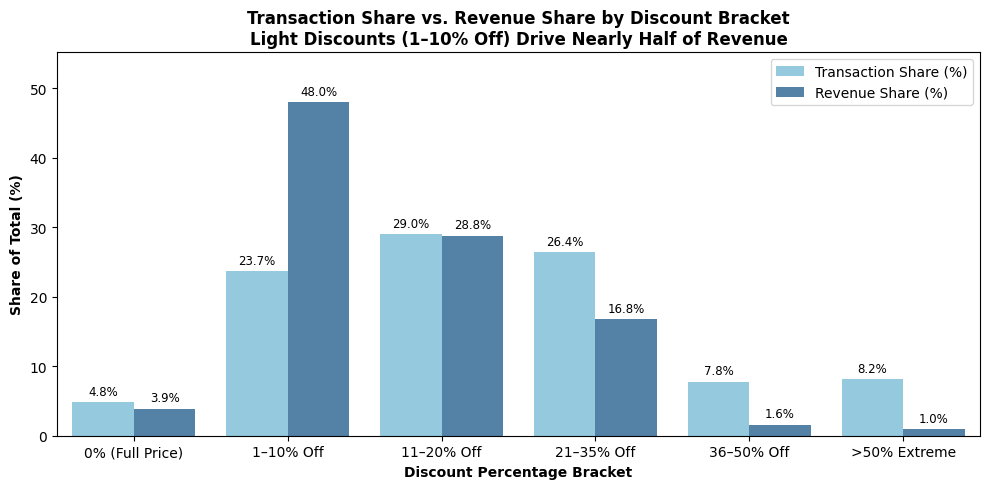

In [ ]:
# 1. Bucket transactions into discount bands (excluding negative markups)
bins = [-0.01, 0, 10, 20, 35, 50, 100]
band_labels = ['0% (Full Price)', '1–10% Off', '11–20% Off', '21–35% Off', '36–50% Off', '>50% Extreme']

valid_discounts = orderlines_prod[orderlines_prod['realized_discount_pct'] >= 0].copy()
valid_discounts['discount_band'] = pd.cut(
    valid_discounts['realized_discount_pct'],
    bins=bins,
    labels=band_labels,
    include_lowest=True
)

# 2. Compute transaction and revenue shares
band_comp = (
    valid_discounts.groupby('discount_band', observed=False)
    .agg(
        tx_count=('id_order', 'count'),
        total_rev=('realized_revenue', 'sum')
    )
    .reindex(band_labels)
    .fillna(0)
    .assign(
        **{
            'Transaction Share (%)': lambda x: (x['tx_count'] / x['tx_count'].sum() * 100).round(1),
            'Revenue Share (%)': lambda x: (x['total_rev'] / x['total_rev'].sum() * 100).round(1)
        }
    )
    .reset_index()
)

# Reshape for grouped barplot
plot_comp = band_comp.melt(
    id_vars='discount_band',
    value_vars=['Transaction Share (%)', 'Revenue Share (%)'],
    var_name='Metric',
    value_name='Share_Pct'
)

# 3. Plot grouped bar chart
plt.figure(figsize=(10, 5))
band_plot = sns.barplot(
    data=plot_comp,
    x='discount_band',
    y='Share_Pct',
    hue='Metric',
    palette={'Transaction Share (%)': 'skyblue', 'Revenue Share (%)': 'steelblue'}
)

# Add percentage labels above each bar
for container in band_plot.containers:
    band_plot.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8.5)

band_plot.set_title(
    'Transaction Share vs. Revenue Share by Discount Bracket\nLight Discounts (1–10% Off) Drive Nearly Half of Revenue',
    fontweight='bold'
)
band_plot.set_xlabel('Discount Percentage Bracket', fontweight='bold')
band_plot.set_ylabel('Share of Total (%)', fontweight='bold')
band_plot.set_ylim(0, plot_comp['Share_Pct'].max() * 1.15)

plt.legend(title='')
plt.tight_layout()
plt.show()

### 4.2 Chart: Realized Checkout Discount by Category

Percentage Discipline Masks Hardware Exposure (Chart 4.2): Breaking down realized checkout discounts by category confirms that steep percentage cuts (25%–40%+) are confined to opened/refurbished stock and low-cost accessories (cables, cases, mounts). Flagship Mac Computers maintain a seemingly disciplined average discount of roughly 10%.

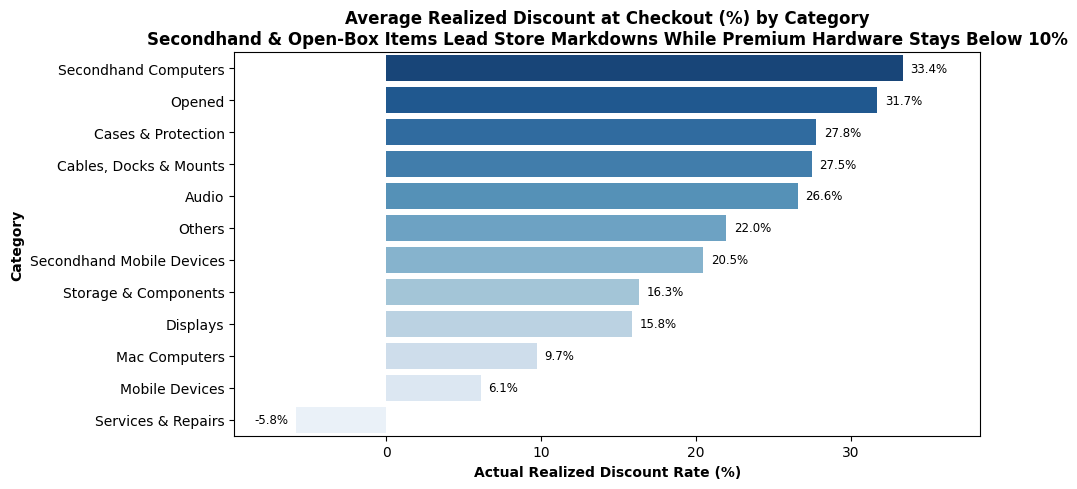

In [ ]:
plot_data = category_perf.sort_values(by='avg_discount_pct', ascending=False)

plt.figure(figsize=(10, 5))
cat_plot = sns.barplot(
    data=plot_data,
    x='avg_discount_pct',
    y='category',
    hue='category',
    palette='Blues_r',
    legend=False
)

# Add percentage labels to the end of each bar
for bar in cat_plot.patches:
    width = bar.get_width()
    if width != 0:
        x_pos = width + 0.5 if width > 0 else width - 0.5
        ha_align = 'left' if width > 0 else 'right'
        cat_plot.text(
            x_pos,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va='center',
            ha=ha_align,
            fontsize=8.5
        )

# Set title and axis labels in bold
cat_plot.set_title('Average Realized Discount at Checkout (%) by Category\nSecondhand & Open-Box Items Lead Store Markdowns While Premium Hardware Stays Below 10%', fontweight='bold')
cat_plot.set_xlabel('Actual Realized Discount Rate (%)', fontweight='bold')
cat_plot.set_ylabel('Category', fontweight='bold')
cat_plot.set_xlim(min(0, plot_data['avg_discount_pct'].min() - 4), plot_data['avg_discount_pct'].max() * 1.15)

plt.tight_layout()
plt.show()

### 4.3 Chart: Realized Revenue vs. Discount Cash Lost (€M)

Total Euro Margin Loss is Concentrated in Flagship Hardware (Chart 4.3): When comparing realized revenue against total discount cash surrendered (€M), Mac Computers account for the single largest total cash loss across the entire catalog — far exceeding the combined Euro loss of every high-percentage accessory category.

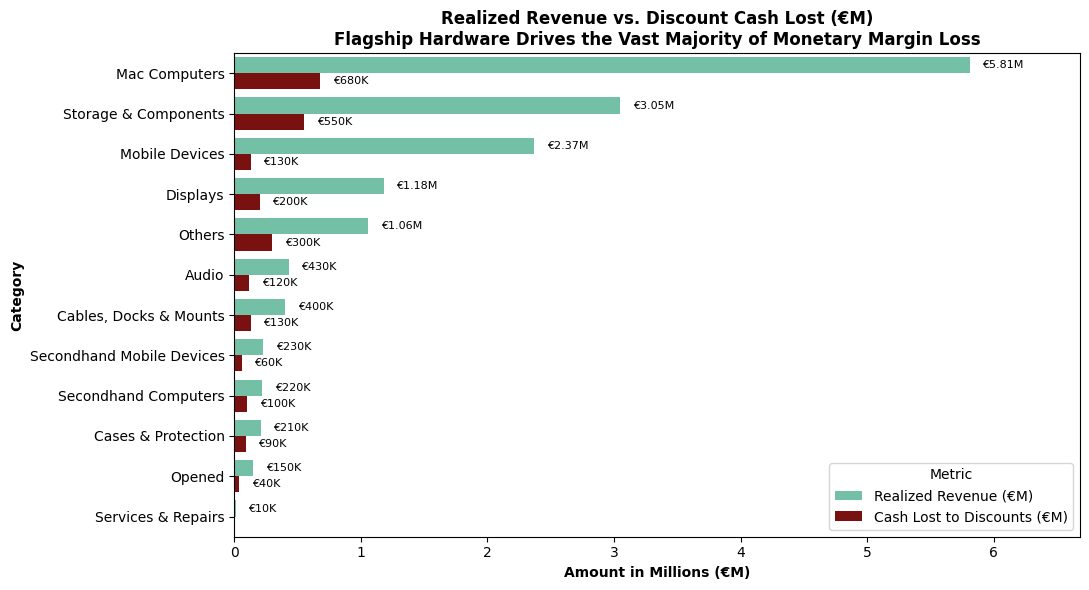

In [ ]:
category_perf_metrics = (
    pd.melt(
        category_perf,
        id_vars='category',
        value_vars=['revenue_m', 'discount_loss_m'],
        var_name='Metric',
        value_name='M_EUR'
    )
    .assign(
        Metric=lambda x: x['Metric'].map({
            'revenue_m': 'Realized Revenue (€M)',
            'discount_loss_m': 'Cash Lost to Discounts (€M)'
        })
    )
)

plt.figure(figsize=(11, 6))
plot1 = sns.barplot(
    data=category_perf_metrics,
    y='category',
    x='M_EUR',
    hue='Metric',
    palette={
        'Realized Revenue (€M)': 'mediumaquamarine',
        'Cash Lost to Discounts (€M)': 'darkred'
    }
)

# Add smart €M / €K value labels to each bar
for bar in plot1.patches:
    width = bar.get_width()
    if width > 0:
        label_txt = f"€{width:.2f}M" if width >= 1.0 else f"€{width * 1000:.0f}K"
        plot1.text(
            width + 0.1,
            bar.get_y() + bar.get_height() / 2,
            label_txt,
            va='center',
            fontsize=8
        )

plot1.set_title(
    'Realized Revenue vs. Discount Cash Lost (€M)\nFlagship Hardware Drives the Vast Majority of Monetary Margin Loss',
    fontweight='bold'
)
plot1.set_xlabel('Amount in Millions (€M)', fontweight='bold')
plot1.set_ylabel('Category', fontweight='bold')
plot1.set_xlim(0, category_perf['revenue_m'].max() * 1.15)

plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### 4.4 Chart: Average Discount Cash Lost Per Unit Sold (€)

Evaluating cash surrendered per unit sold highlights the core pricing asymmetry: a 30%+ discount on an accessory surrenders single-digit pocket change, whereas a "modest" ~10% discount on a high-base-price Mac Computer surrenders triple-digit cash margin on every unit sold.

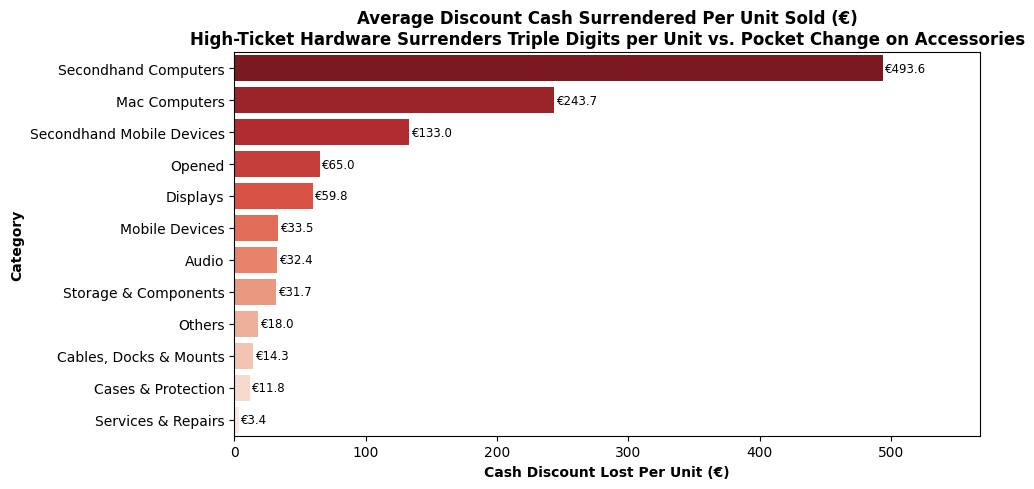

In [ ]:
plt.figure(figsize=(10, 5))
plot3 = sns.barplot(
    data=category_perf.sort_values(by='loss_per_unit', ascending=False),
    y='category',
    x='loss_per_unit',
    hue='category',
    palette='Reds_r',
    legend=False
)

# Value labels on bars
for bar in plot3.patches:
    width = bar.get_width()
    if width > 0:
        plot3.text(
            width + 2,
            bar.get_y() + bar.get_height() / 2,
            f"€{width:,.1f}",
            va='center',
            fontsize=8.5
        )

plot3.set_title(
    'Average Discount Cash Surrendered Per Unit Sold (€)\nHigh-Ticket Hardware Surrenders Triple Digits per Unit vs. Pocket Change on Accessories',
    fontweight='bold'
)
plot3.set_xlabel('Cash Discount Lost Per Unit (€)', fontweight='bold')
plot3.set_ylabel('Category', fontweight='bold')
plot3.set_xlim(0, category_perf['loss_per_unit'].max() * 1.15)

plt.tight_layout()
plt.show()

## 5. Strategic Recommendations for Leadership

Core Finding: The "Percentage Illusion" on High-Ticket Hardware
Our analysis proves that aggressive clearance markdowns (30%–50%+) on accessories and open-box items are not what erode store profitability. Instead, the single largest financial drain comes from seemingly modest ~10% discounts on Mac Computers, which surrender triple-digit cash margins on every unit sold.

Strategic Action Plan:

1. Cap Percentage Discounts on Core Hardware (Max 5%–7%): Immediately tighten promotional ceilings on Mac Computers and flagship Apple hardware from ~10% down to a strict 5%–7% cap to protect unit economics.

2. Shift from Percentage to Fixed-Euro Framing (€100–€150 Off): Because "5%–7% off" lacks psychological appeal to retail buyers, reframe hardware promotions as fixed-sum rebates (e.g., €100 or €150 off). A €100–€150 rebate feels substantial to the customer while cutting ENIAC's per-unit cash surrender significantly compared to an uncapped 10% markdown on a €2,000+ machine.

3. Preserve High-Percentage Promotions for Long-Tail & Clearance Inventory: Continue leveraging 25%+ discounts exclusively on low-base-price accessories, cables, and opened/refurbished stock where percentage optics drive volume at minimal Euro cost.



## 6. Appendix / Extra

### 6.1 Chart: Discount Depth vs. Price Tier
Maps average realized discount percentages against catalog price tiers and unit volume, visually confirming the structural split between low-cost, high-discount accessories and high-ticket, tightly bounded core hardware.

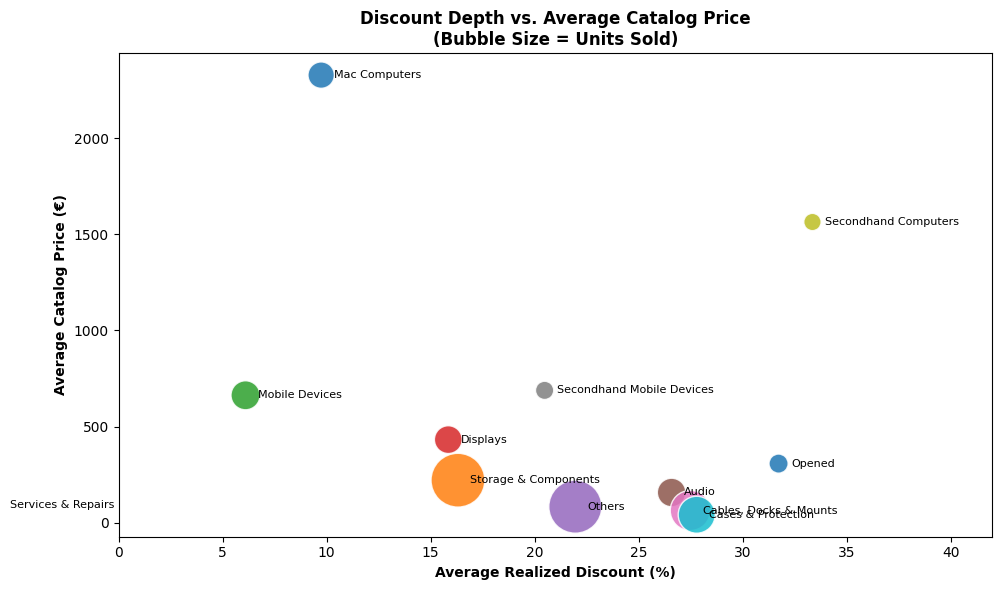

In [ ]:
plt.figure(figsize=(10, 6))
scatter_plot = sns.scatterplot(
    data=category_perf,
    x='avg_discount_pct',
    y='avg_catalog_price',
    size='units_sold',
    sizes=(150, 1500),
    hue='category',
    palette='tab10',
    alpha=0.85,
    legend=False
)

# Add data labels
for _, row in category_perf.iterrows():
    scatter_plot.text(
        row['avg_discount_pct'] + 0.6,
        row['avg_catalog_price'],
        row['category'],
        fontsize=8,
        va='center'
    )

scatter_plot.set_title(
    'Discount Depth vs. Average Catalog Price\n(Bubble Size = Units Sold)',
    fontweight='bold'
)
scatter_plot.set_xlabel('Average Realized Discount (%)', fontweight='bold')
scatter_plot.set_ylabel('Average Catalog Price (€)', fontweight='bold')
scatter_plot.set_xlim(0, 42)

plt.tight_layout()
plt.show()

### 6.2 Deep-Dive into Core iPhone Lifecycle & Discount Buckets

Isolates core smartphone models (iPhone 5–8) across time and discount brackets, illustrating how promotional markdowns scale over a product's lifecycle without altering the macro margin conclusions established in Section 4.

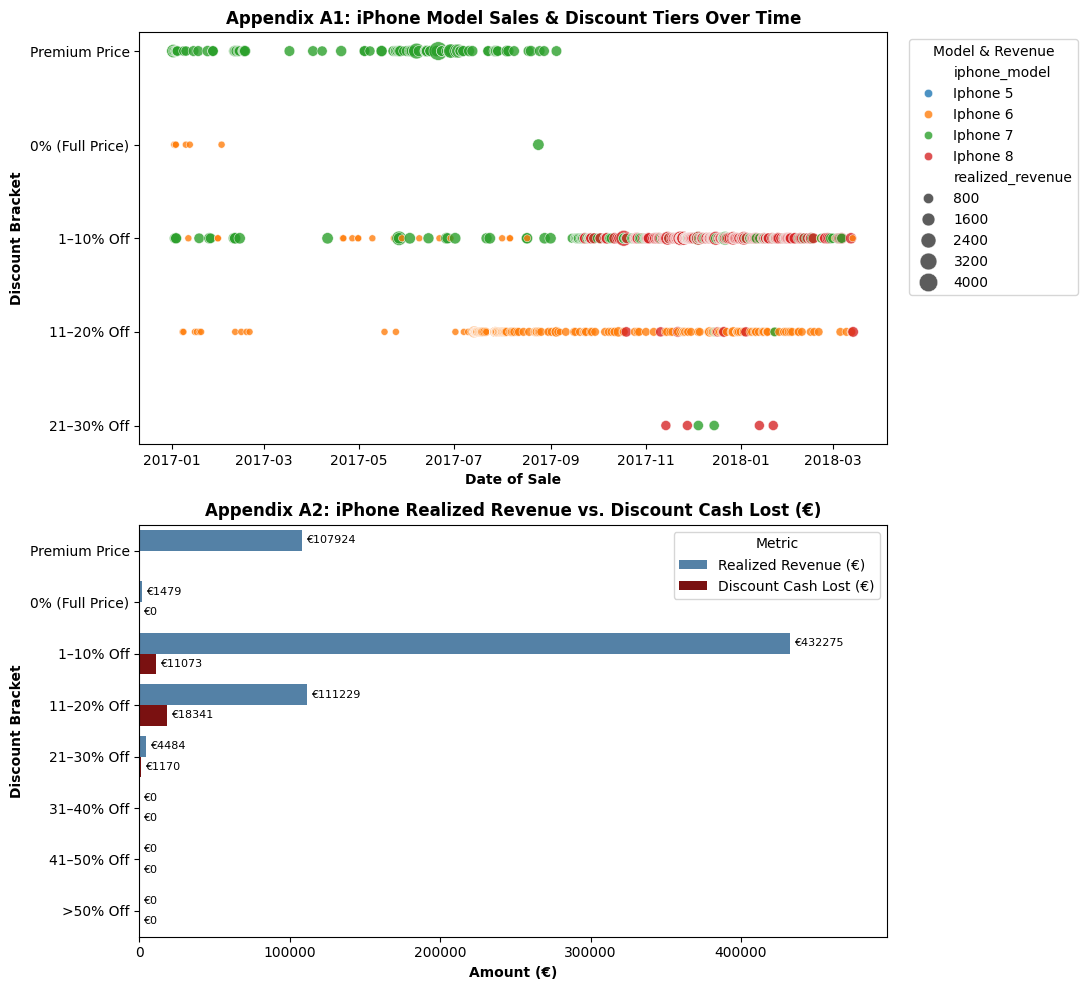

In [ ]:
# 1. Extract iPhone 5–8 models cleanly via regex
iphone_df = orderlines_prod[
    orderlines_prod['name'].str.contains(r'^.{0,7}apple iphone [5-8]\b', case=False, na=False)
].copy()

iphone_df['iphone_model'] = (
    iphone_df['name']
    .str.extract(r'(?i)(iphone [5-8])')[0]
    .str.title()
)

# 2. Bucket realized discount percentages
bins = [-np.inf, -0.01, 0, 10, 20, 30, 40, 50, np.inf]
labels = ['Premium Price', '0% (Full Price)', '1–10% Off', '11–20% Off', '21–30% Off', '31–40% Off', '41–50% Off', '>50% Off']

iphone_df['discount_bucket'] = pd.cut(
    iphone_df['realized_discount_pct'],
    bins=bins,
    labels=labels
)

# 3. Aggregate revenue & discount loss by bucket
bucket_summary = (
    iphone_df.groupby('discount_bucket', observed=False)
    .agg(
        total_revenue=('realized_revenue', 'sum'),
        total_discount_loss=('discount_loss', 'sum')
    )
    .reset_index()
    .melt(id_vars='discount_bucket', var_name='Metric', value_name='EUR')
    .assign(Metric=lambda x: x['Metric'].map({
        'total_revenue': 'Realized Revenue (€)',
        'total_discount_loss': 'Discount Cash Lost (€)'
    }))
)

# 4. Plot two-panel summary matching notebook styling
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 10))

# Panel 1: Model lifecycle over time
sns.scatterplot(
    data=iphone_df,
    x='date',
    y='discount_bucket',
    hue='iphone_model',
    hue_order=['Iphone 5', 'Iphone 6', 'Iphone 7', 'Iphone 8'],
    palette='tab10',
    size='realized_revenue',
    sizes=(25, 180),
    alpha=0.8,
    ax=ax1
)
ax1.set_title('iPhone Model Sales & Discount Tiers Over Time', fontweight='bold')
ax1.set_xlabel('Date of Sale', fontweight='bold')
ax1.set_ylabel('Discount Bracket', fontweight='bold')
ax1.legend(title='Model & Revenue', bbox_to_anchor=(1.02, 1), loc='upper left')

# Panel 2: Revenue vs. Discount Loss by Bracket
bar_plot = sns.barplot(
    data=bucket_summary,
    y='discount_bucket',
    x='EUR',
    hue='Metric',
    palette={'Realized Revenue (€)': 'steelblue', 'Discount Cash Lost (€)': 'darkred'},
    ax=ax2
)
for container in bar_plot.containers:
    bar_plot.bar_label(container, fmt='€%.0f', padding=3, fontsize=8)

ax2.set_title('iPhone Realized Revenue vs. Discount Cash Lost (€)', fontweight='bold')
ax2.set_xlabel('Amount (€)', fontweight='bold')
ax2.set_ylabel('Discount Bracket', fontweight='bold')
ax2.set_xlim(0, bucket_summary['EUR'].max() * 1.15)
ax2.legend(title='Metric')

plt.tight_layout()
plt.show()